# MwC 03 — deviation maps and spatial replication

Create the formal 26-ROI age/sex-adjusted MwC deviation heatmap and TRD1–TRD2 replication result.

- Formal analysis universe: 12 cortical + 14 limbic ROIs (26 nodes)
- Cross-network connectivity: 12 × 14 = 168 edges
- Pipeline: `mwc`; step 3 of 5
- Run mode: standalone; all prerequisite steps load automatically in the same kernel.


In [1]:
from pathlib import Path
import os

_repo = Path(os.environ.get("METAFL_ROOT", Path.cwd())).resolve()
if not (_repo / "pipeline_steps").is_dir() and (_repo.parent / "pipeline_steps").is_dir():
    _repo = _repo.parent
if not (_repo / "pipeline_steps").is_dir():
    raise FileNotFoundError("Set METAFL_ROOT to the repository root")
os.environ["METAFL_ROOT"] = str(_repo)
os.chdir(_repo)

def _run_step(relative_path):
    _path = _repo / "pipeline_steps" / relative_path
    _code = compile(_path.read_text(encoding="utf-8"), str(_path), "exec")
    exec(_code, get_ipython().user_ns)
_run_step("mwc_01_setup_recompute.py")
_run_step("mwc_02_subject_level.py")


,input,size_kib
0,03_compute_normative_sc_mwc.py,12.4
1,session_gcmi_pet_AAL3_144.npz,17095.9
2,normative_SC_top10_mask.npz,53.7
3,subject_level_corticolimbic26_normativeSC10_Mw...,120.9
4,subject_level_AAL3_144_normativeSC10_MwC_wide....,288.0
5,validation_report.json,0.2
6,corticolimbic_12x14_ROI_definition.csv,0.6
7,clinical_data.xlsx,10.9
8,subject_level_corticolimbic26_age_sex_adjusted...,133.5


{
  "full_144": "/Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/mwc/recomputed_normative_sc/subject_level_AAL3_144_normativeSC10_MwC_wide.csv.gz",
  "selected_26": "/Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/mwc/recomputed_normative_sc/subject_level_corticolimbic26_normativeSC10_MwC_wide.csv",
  "validation": "/Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/mwc/recomputed_normative_sc/calculation_validation_report.json"
}
PASS: AAL3-144 normative-SC-constrained MwC recomputed before 26-ROI extraction


,check,passed
0,sessions_253,True
1,retained_AAL3_nodes_144,True
2,fixed_dTOR_normative_SC_edges_1030,True
3,gcmi_floor_bits_0p01,True
4,row_normalization_error_below_1e_12,True
5,all_144_nodes_computed_before_26_extraction,True
6,isolated_nodes_remain_missing,True
7,full_144_matches_validated_reference,True
8,selected_26_matches_validated_reference,True


,quantity,value
0,upstream paired sessions,253.0
1,clinical sessions,253.0
2,ROIs per session,26.0
3,long-table rows,6578.0
4,all-144 to 26 extraction maximum absolute error,0.0


,node_index,network,AAL3_ID,ROI
0,1,cortical,3,Frontal_Sup_2_L
1,2,cortical,4,Frontal_Sup_2_R
2,3,cortical,5,Frontal_Mid_2_L
3,4,cortical,6,Frontal_Mid_2_R
4,5,cortical,19,Frontal_Sup_Medial_L
5,6,cortical,20,Frontal_Sup_Medial_R
6,7,cortical,21,Frontal_Med_Orb_L
7,8,cortical,22,Frontal_Med_Orb_R
8,9,cortical,25,OFCmed_L
9,10,cortical,26,OFCmed_R


## Preamble


In [2]:
"""MwC 03 — formal 26-ROI deviation maps and spatial replication."""


'MwC 03 — formal 26-ROI deviation maps and spatial replication.'

## Source 10


,n_ROIs,cortical_ROIs,limbic_ROIs,TRD1_n,TRD2_n,pearson_r,pearson_p_two_sided,same_direction_agreement,DSC_weighted,MwC_input
0,26,12,14,35,85,0.950756,0.0,0.846154,0.831964,HC-only age/sex residual z scores; 26 ROIs ext...


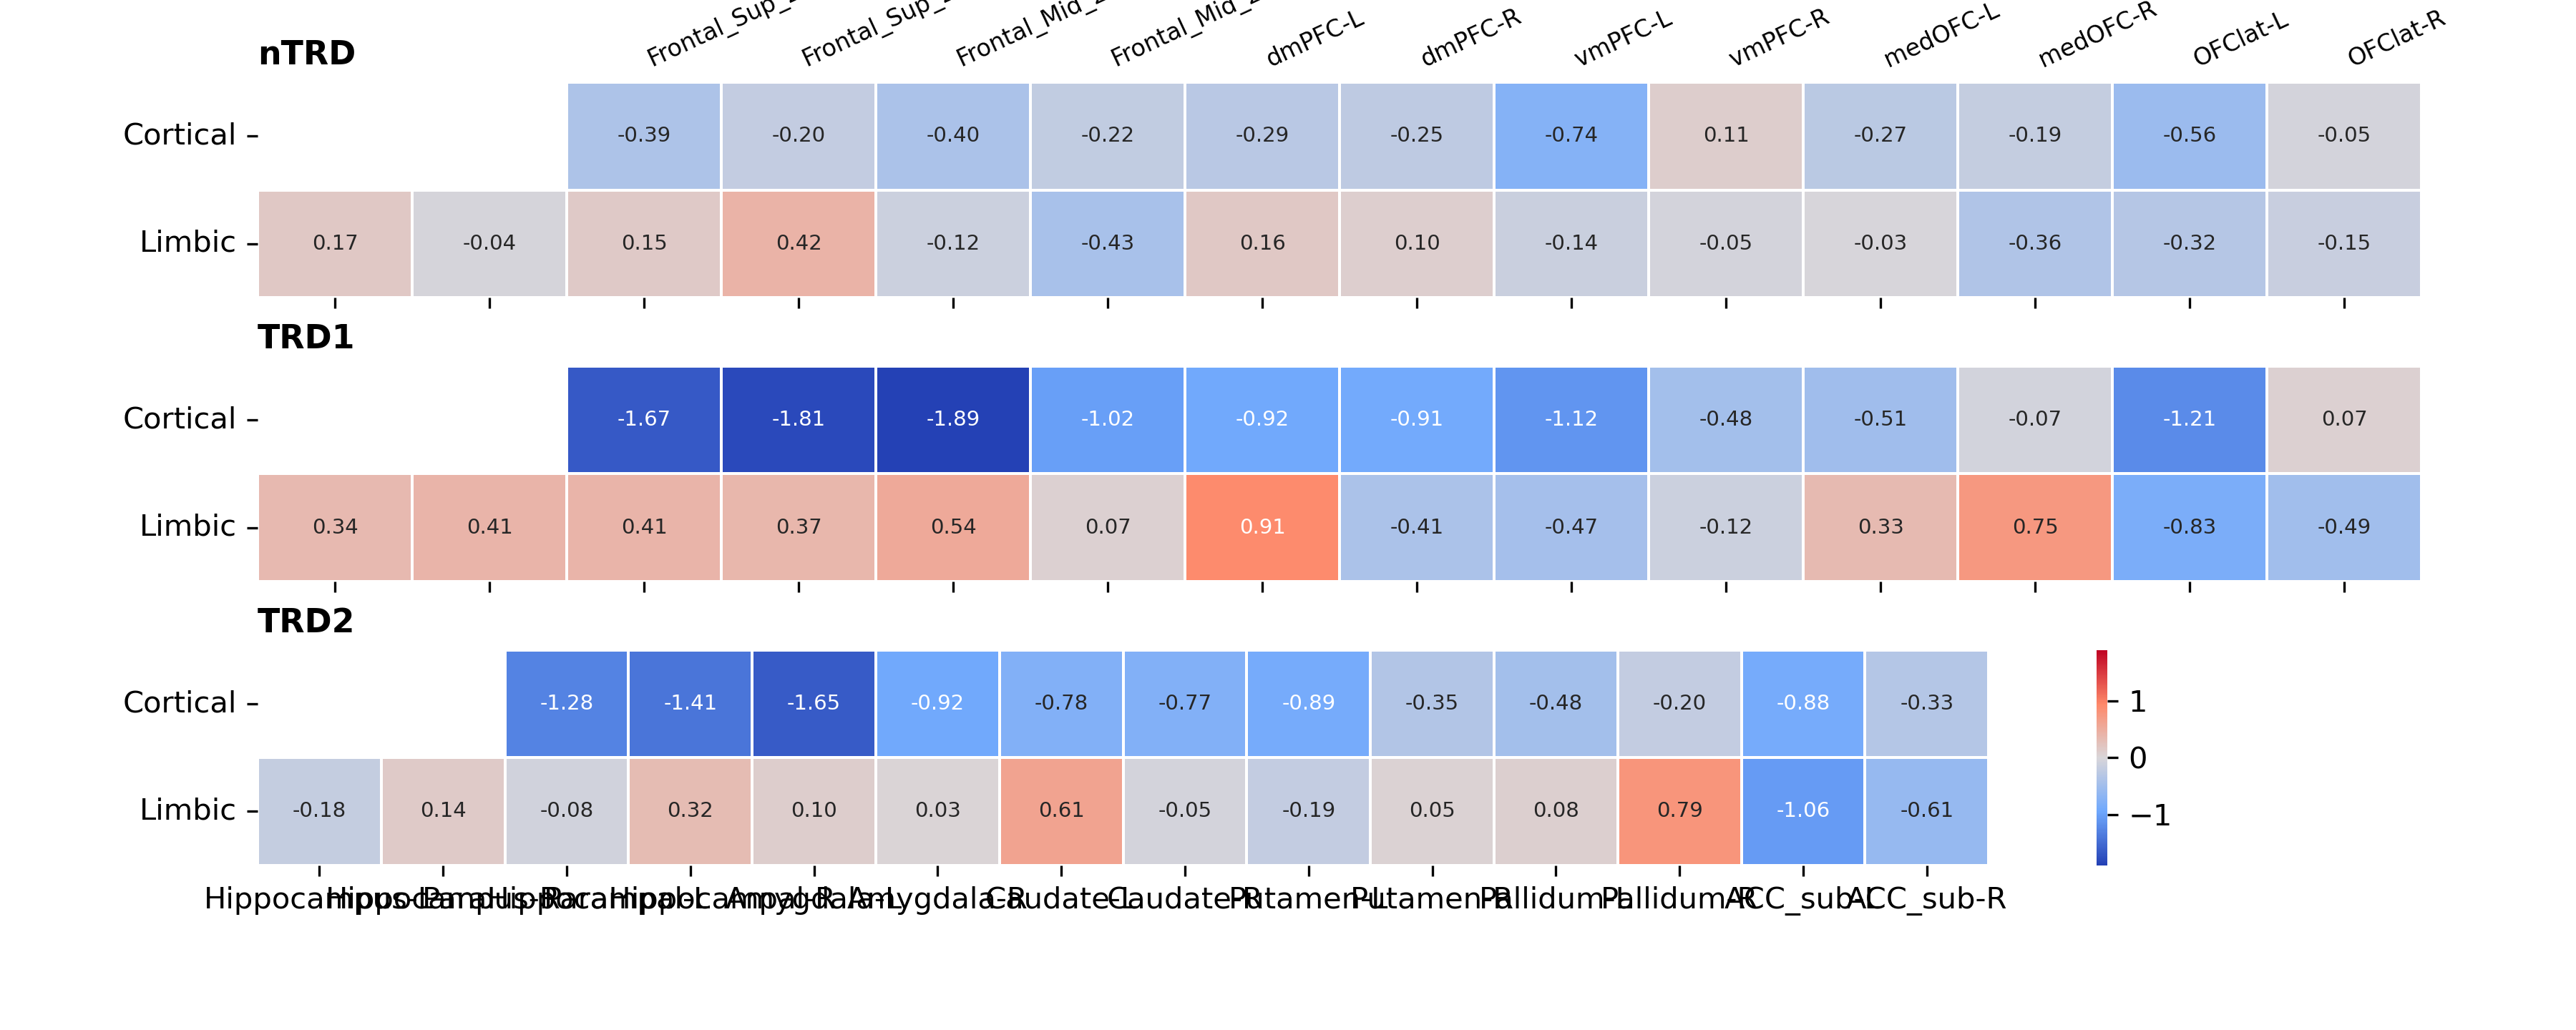

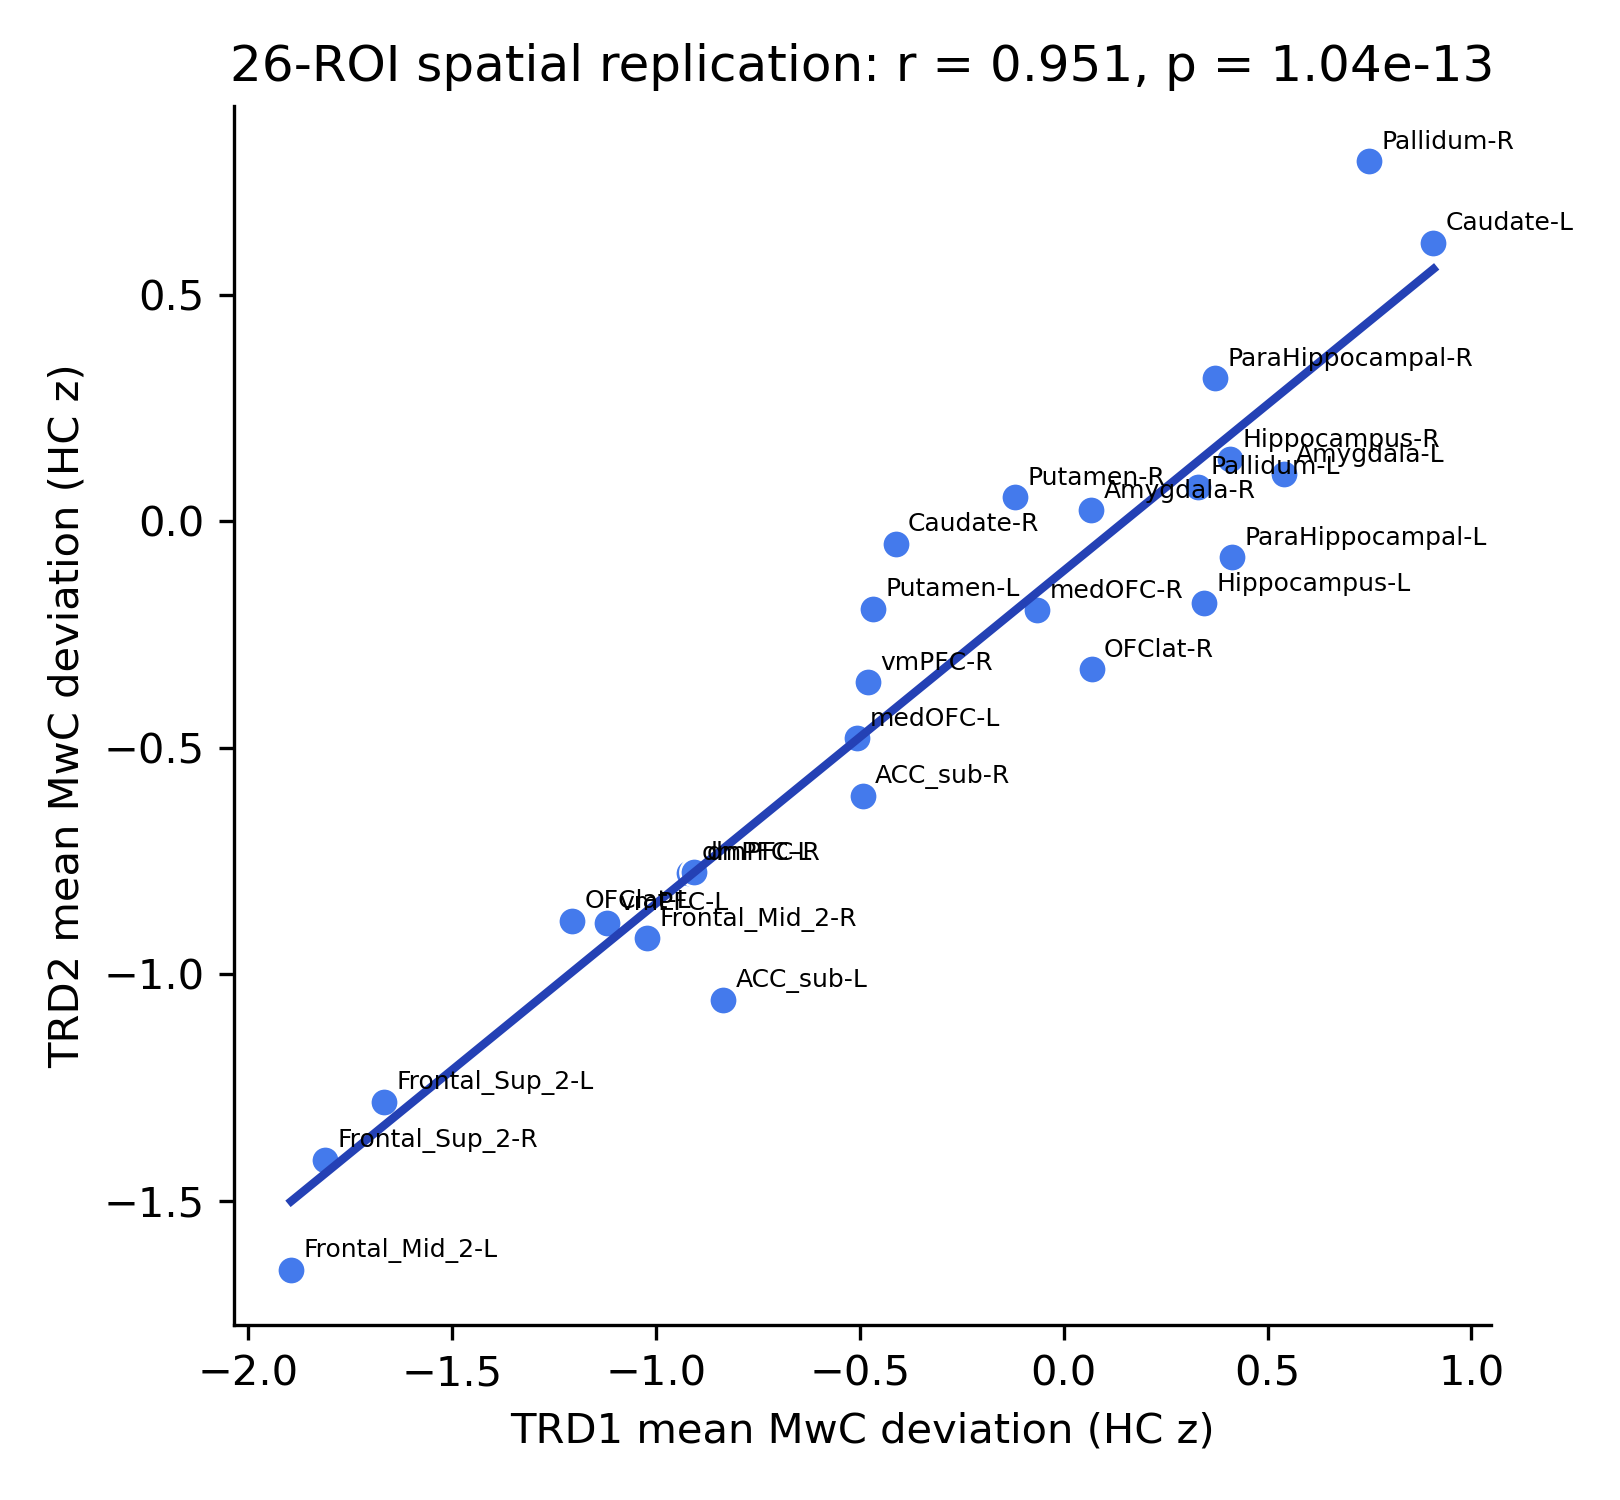

In [3]:
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

mwc_adjusted_26 = pd.read_csv(MWC_ADJUSTED_26_FILE)
mwc_adjusted_columns = [f"MwC_{name}" for name in roi.ROI]
assert len(mwc_adjusted_columns) == 26
assert set(mwc_adjusted_columns).issubset(mwc_adjusted_26.columns)
assert len(mwc_adjusted_26) == 253

mwc_baseline_26 = mwc_adjusted_26.loc[
    mwc_adjusted_26.session.eq("ses-01")
    & mwc_adjusted_26.analysis_cohort.isin(["nTRD", "TRD1", "TRD2"])
].copy()
assert mwc_baseline_26.groupby("analysis_cohort").size().to_dict() == {
    "TRD1": 35, "TRD2": 85, "nTRD": 25,
}
mwc_group_means_26 = {
    group: mwc_baseline_26.loc[
        mwc_baseline_26.analysis_cohort.eq(group), mwc_adjusted_columns
    ].mean().to_numpy(float)
    for group in ["nTRD", "TRD1", "TRD2"]
}

trd1_vector = mwc_group_means_26["TRD1"]
trd2_vector = mwc_group_means_26["TRD2"]
pearson_r, pearson_p = stats.pearsonr(trd1_vector, trd2_vector)
same_direction = float(np.mean(np.sign(trd1_vector) == np.sign(trd2_vector)))
weighted_dsc = float(
    2 * np.sum(np.minimum(np.abs(trd1_vector), np.abs(trd2_vector)))
    / np.sum(np.abs(trd1_vector) + np.abs(trd2_vector))
)
mwc_spatial_summary = pd.DataFrame([{
    "n_ROIs": 26, "cortical_ROIs": 12, "limbic_ROIs": 14,
    "TRD1_n": 35, "TRD2_n": 85,
    "pearson_r": float(pearson_r), "pearson_p_two_sided": float(pearson_p),
    "same_direction_agreement": same_direction, "DSC_weighted": weighted_dsc,
    "MwC_input": "HC-only age/sex residual z scores; 26 ROIs extracted after all-144 computation",
}])
mwc_spatial_summary.to_csv(MWC_SPATIAL_SUMMARY_FILE, index=False)

mwc_mean_rows = []
for group, values in mwc_group_means_26.items():
    for roi_row, value in zip(roi.itertuples(), values):
        mwc_mean_rows.append({
            "group": group, "network": roi_row.network,
            "AAL3_ID": int(roi_row.AAL3_ID), "ROI": roi_row.ROI,
            "mean_age_sex_adjusted_MwC_deviation_z": float(value),
        })
pd.DataFrame(mwc_mean_rows).to_csv(
    OUTPUT_DIR / "nTRD_TRD1_TRD2_normativeSC_MwC_26ROI_mean_deviations.csv",
    index=False,
)

heatmap_cmap = LinearSegmentedColormap.from_list(
    "scientific_blue_red",
    ["#2441B5", "#6FA8FD", "#D9D6D9", "#FE8869", "#BF0323"], N=256,
)
cortical_index = roi.index[roi.network.eq("cortical")].to_numpy()
limbic_index = roi.index[roi.network.eq("limbic")].to_numpy()
short_labels = [display_roi_name(name).replace("_L", "-L").replace("_R", "-R") for name in roi.ROI]
offset = len(limbic_index) - len(cortical_index)
matrices = {}
for group, values in mwc_group_means_26.items():
    matrix = np.full((2, 14), np.nan)
    matrix[0, offset:] = values[cortical_index]
    matrix[1, :] = values[limbic_index]
    matrices[group] = matrix
vmax = float(np.nanmax(np.abs(np.concatenate([value.ravel() for value in matrices.values()]))))

fig, axes = plt.subplots(3, 1, figsize=(12.0, 4.8), sharex=True)
for ax, group in zip(axes, ["nTRD", "TRD1", "TRD2"]):
    sns.heatmap(
        matrices[group], mask=np.isnan(matrices[group]), ax=ax, cmap=heatmap_cmap,
        vmin=-vmax, vmax=vmax, center=0, annot=True, fmt=".2f",
        annot_kws={"fontsize": 7}, linewidths=.5, linecolor="white",
        cbar=group == "TRD2", yticklabels=["Cortical", "Limbic"], xticklabels=False,
    )
    ax.set_title(group, loc="left", fontsize=11, fontweight="bold")
    ax.tick_params(axis="y", rotation=0)
for column, index in enumerate(cortical_index, start=offset):
    axes[0].text(column + .5, -.10, short_labels[index], rotation=25,
                 ha="left", va="bottom", fontsize=8, clip_on=False)
axes[0].set_xticks(np.arange(14) + .5)
axes[0].set_xticklabels([short_labels[i] for i in limbic_index], rotation=25, ha="left")
fig.subplots_adjust(left=.10, right=.94, top=.92, bottom=.16, hspace=.32)
fig.savefig(MWC_DEVIATION_HEATMAP, dpi=300, facecolor="white")
fig.savefig(MWC_DEVIATION_HEATMAP.with_suffix(".pdf"), facecolor="white")
plt.close(fig)

fig, ax = plt.subplots(figsize=(5.4, 5.0))
ax.scatter(trd1_vector, trd2_vector, s=46, color="#447AEC", edgecolor="white", linewidth=.6)
fit = np.polyfit(trd1_vector, trd2_vector, 1)
xline = np.linspace(trd1_vector.min(), trd1_vector.max(), 100)
ax.plot(xline, np.polyval(fit, xline), color="#2441B5", linewidth=2)
for x, y, label in zip(trd1_vector, trd2_vector, short_labels):
    ax.annotate(label, (x, y), xytext=(3, 3), textcoords="offset points", fontsize=6)
ax.set_xlabel("TRD1 mean MwC deviation (HC z)")
ax.set_ylabel("TRD2 mean MwC deviation (HC z)")
ax.set_title(f"26-ROI spatial replication: r = {pearson_r:.3f}, p = {pearson_p:.3g}")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(MWC_SPATIAL_FIGURE, dpi=300, facecolor="white")
fig.savefig(MWC_SPATIAL_FIGURE.with_suffix(".pdf"), facecolor="white")
plt.close(fig)

assert int(mwc_spatial_summary.iloc[0].n_ROIs) == 26
display(mwc_spatial_summary.round(6))
display(Image(filename=str(MWC_DEVIATION_HEATMAP), width=1800))
display(Image(filename=str(MWC_SPATIAL_FIGURE), width=900))


## Results preview

Key numerical tables and figures generated by this step are displayed below. The full-resolution files remain under `outputs/`.


### Key tables

**MwC spatial replication**  
`outputs/mwc/TRD1_TRD2_normativeSC_MwC_26ROI_spatial_summary.csv` — 1 rows × 10 columns

,n_ROIs,cortical_ROIs,limbic_ROIs,TRD1_n,TRD2_n,pearson_r,pearson_p_two_sided,same_direction_agreement,DSC_weighted,MwC_input
0,26,12,14,35,85,0.950756,1.042691e-13,0.846154,0.831964,HC-only age/sex residual z scores; 26 ROIs extracted aft...


**Group mean MwC deviations**  
`outputs/mwc/nTRD_TRD1_TRD2_normativeSC_MwC_26ROI_mean_deviations.csv` — 78 rows × 5 columns

,group,network,AAL3_ID,ROI,mean_age_sex_adjusted_MwC_deviation_z
0,nTRD,cortical,3,Frontal_Sup_2_L,-0.392507
1,nTRD,cortical,4,Frontal_Sup_2_R,-0.203867
2,nTRD,cortical,5,Frontal_Mid_2_L,-0.403144
3,nTRD,cortical,6,Frontal_Mid_2_R,-0.218848
4,nTRD,cortical,19,Frontal_Sup_Medial_L,-0.285231
5,nTRD,cortical,20,Frontal_Sup_Medial_R,-0.251405
6,nTRD,cortical,21,Frontal_Med_Orb_L,-0.740025
7,nTRD,cortical,22,Frontal_Med_Orb_R,0.114952
8,nTRD,cortical,25,OFCmed_L,-0.274124
9,nTRD,cortical,26,OFCmed_R,-0.190415


### Figures

**`outputs/mwc/figures/Figure_nTRD_TRD1_TRD2_normativeSC_MwC_26ROI_deviation_heatmap.png`**

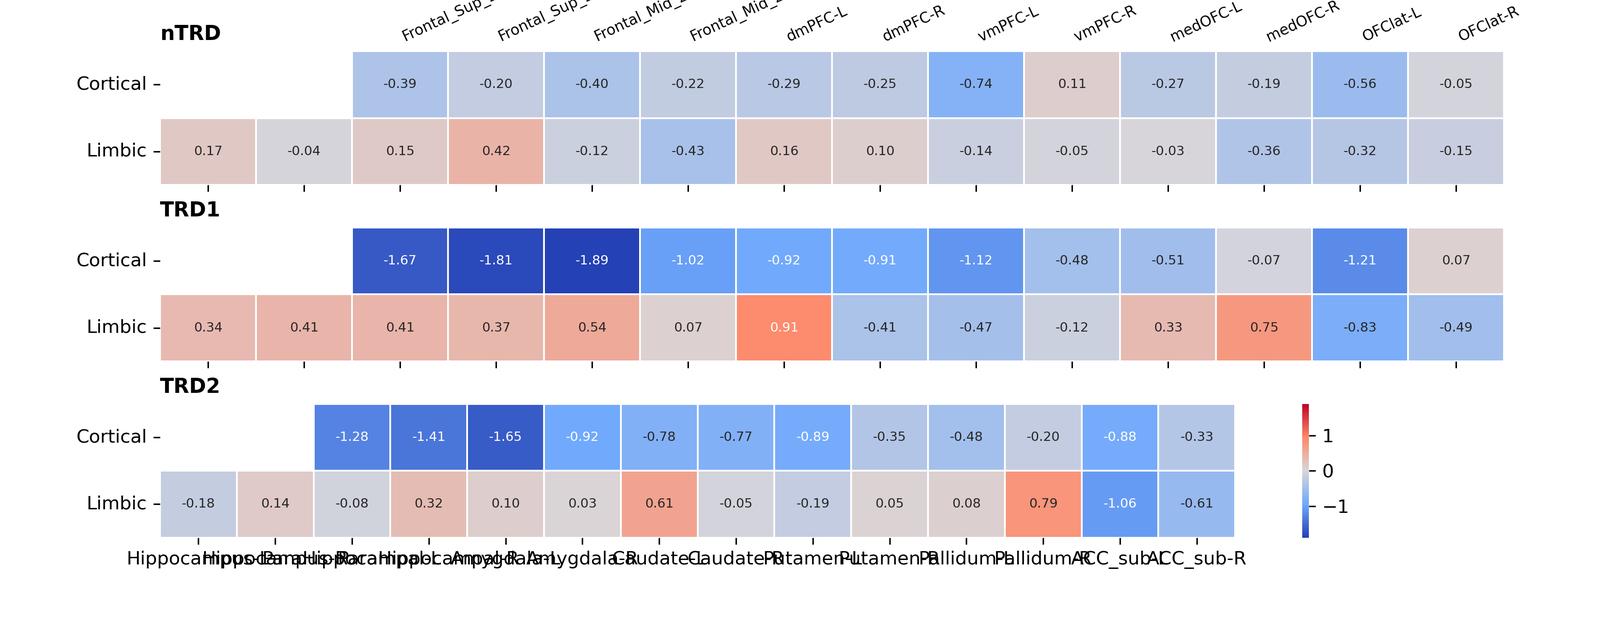

**`outputs/mwc/figures/Figure_TRD1_TRD2_normativeSC_MwC_26ROI_spatial_correlation.png`**

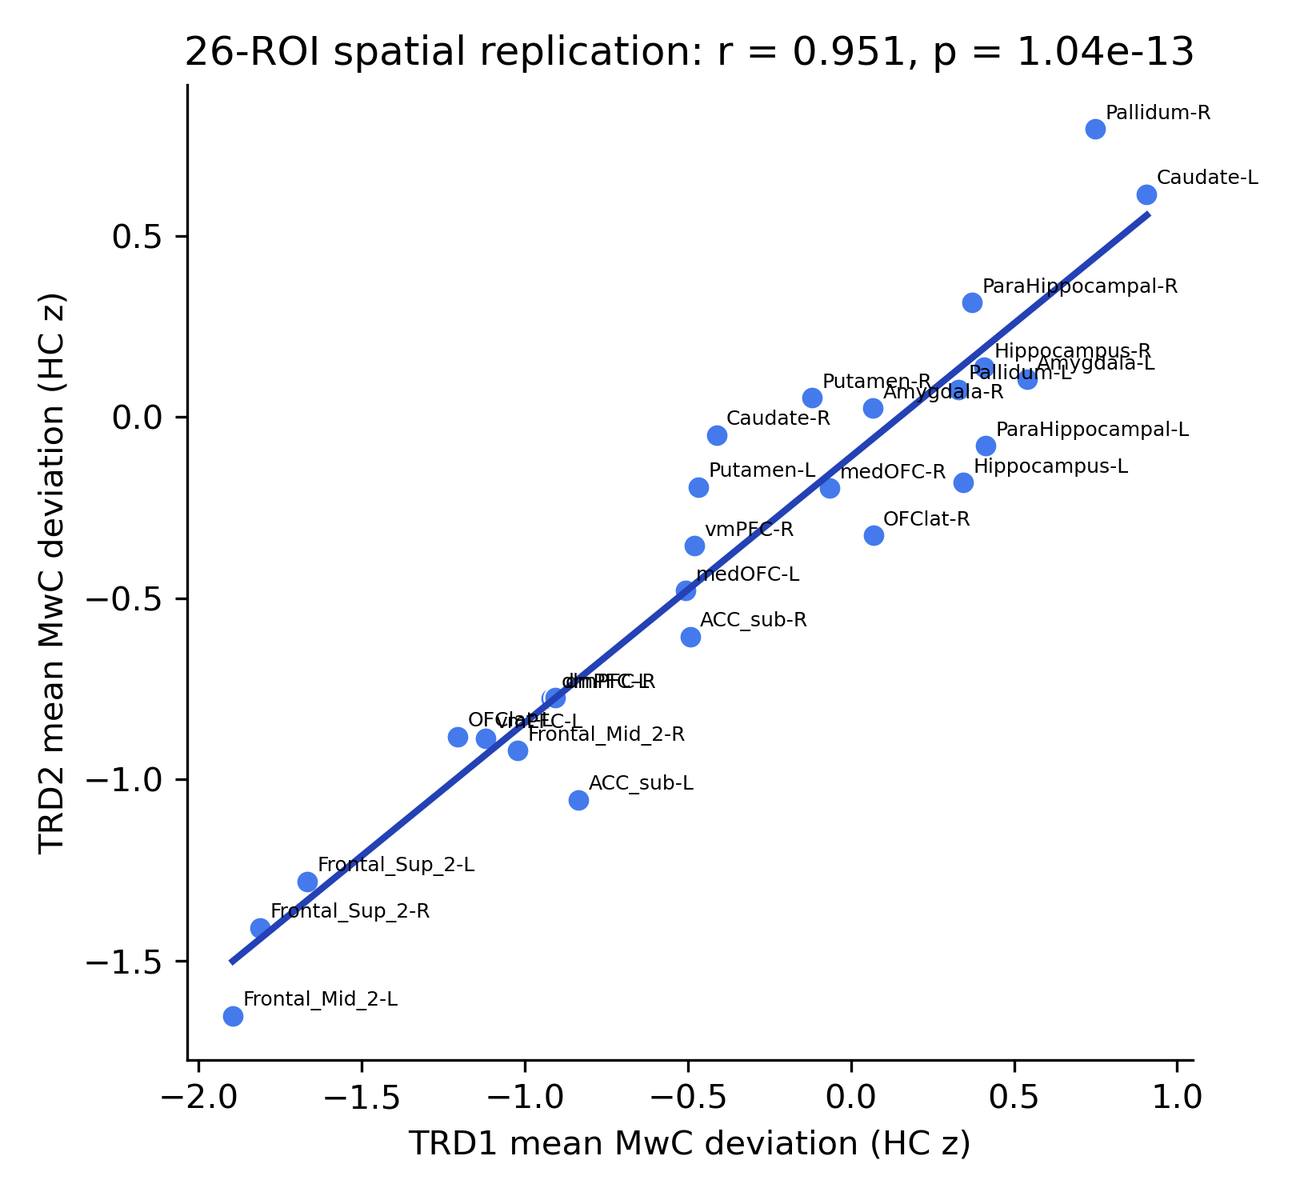

In [4]:
from io import BytesIO
import json as _preview_json
import pandas as _preview_pd
from PIL import Image as PILImage
from IPython.display import Image as NotebookImage, Markdown, display

_inline_table_specs = [{'title': 'MwC spatial replication', 'path': 'outputs/mwc/TRD1_TRD2_normativeSC_MwC_26ROI_spatial_summary.csv'}, {'title': 'Group mean MwC deviations', 'path': 'outputs/mwc/nTRD_TRD1_TRD2_normativeSC_MwC_26ROI_mean_deviations.csv', 'max_rows': 26}]
_inline_figure_paths = ['outputs/mwc/figures/Figure_nTRD_TRD1_TRD2_normativeSC_MwC_26ROI_deviation_heatmap.png', 'outputs/mwc/figures/Figure_TRD1_TRD2_normativeSC_MwC_26ROI_spatial_correlation.png']

display(Markdown("### Key tables"))
for _table_spec in _inline_table_specs:
    _relative_table = _table_spec["path"]
    _table_path = _repo / _relative_table
    if not _table_path.is_file():
        raise FileNotFoundError(_table_path)
    if _table_path.suffix.lower() == ".csv":
        _preview_table = _preview_pd.read_csv(_table_path)
    elif _table_path.suffix.lower() in {".xlsx", ".xls"}:
        _preview_table = _preview_pd.read_excel(
            _table_path, sheet_name=_table_spec.get("sheet", 0)
        )
    elif _table_path.suffix.lower() == ".json":
        _payload = _preview_json.loads(_table_path.read_text(encoding="utf-8"))
        _checks = _payload.get("checks", _payload)
        _preview_table = _preview_pd.DataFrame(
            {"item": list(_checks), "value": list(_checks.values())}
        ) if isinstance(_checks, dict) else _preview_pd.json_normalize(_payload)
    else:
        raise ValueError(f"Unsupported table format: {_table_path.suffix}")
    if _table_spec.get("query"):
        _preview_table = _preview_table.query(_table_spec["query"]).reset_index(drop=True)
    _max_rows = int(_table_spec.get("max_rows", 40))
    display(Markdown(
        f"**{_table_spec['title']}**  \n"
        f"`{_relative_table}` — {len(_preview_table)} rows × {len(_preview_table.columns)} columns"
    ))
    with _preview_pd.option_context("display.max_columns", 40, "display.max_colwidth", 60):
        display(_preview_table.head(_max_rows))

if _inline_figure_paths:
    display(Markdown("### Figures"))
for _relative_figure in _inline_figure_paths:
    _figure_path = _repo / _relative_figure
    if not _figure_path.is_file():
        raise FileNotFoundError(_figure_path)
    with PILImage.open(_figure_path) as _source_image:
        _preview_image = _source_image.convert("RGB")
        _preview_image.thumbnail((1600, 1200), PILImage.Resampling.LANCZOS)
        _preview_buffer = BytesIO()
        _preview_image.save(_preview_buffer, format="PNG", optimize=True)
    display(Markdown(f"**`{_relative_figure}`**"))
    display(NotebookImage(data=_preview_buffer.getvalue(), format="png"))
